# 02 - ¿Qué materias primas determinan el precio de cada equipo?

**Pregunta:** la gerencia sospecha que el precio de los equipos depende de algunas materias primas,
pero no sabe de cuáles ni en qué medida. Hay que separar lo que **explica** el precio de lo que es **ruido**.

**Estrategia:** no confiar en un solo método. Se usan cinco enfoques distintos y se revisa si llegan a la misma conclusión:

| # | Método | Qué responde |
|---|---|---|
| 1 | Regresión en niveles (OLS) | ¿Cuánto pesa cada insumo y es significativo? |
| 2 | Cointegración | ¿La relación en niveles es real o espuria? |
| 3 | Pesos no negativos (NNLS) | ¿Cuál es la "receta" del equipo en unidades de insumo? |
| 4 | Regresión en cambios + Lasso | ¿Se confirma con cambios mensuales? ¿Qué variables descarta un método automático? |
| 5 | Estabilidad y validación fuera de muestra | ¿La relación se mantiene en el tiempo y predice datos que no vio? |

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src import datos, relacion as rel
from src.graficas import COLORES, estilo, guardar

estilo()
pd.set_option("display.float_format", "{:,.4f}".format)

hist = datos.cargar_historico()
mensual = datos.a_mensual(hist)
EQUIPOS = ["Equipo1", "Equipo2"]

## 1. Estacionariedad

Si las series tienen tendencia (no son estacionarias), una regresión puede dar una relación falsa.
La prueba de **Dickey-Fuller aumentada (ADF)**: p < 0.05 indica estacionaria.

In [2]:
pd.DataFrame({c: rel.adf(hist[c]) for c in hist.columns}).T

,estadistico,p_valor,estacionaria
X,-1.7052,0.4284,False
Y,-2.5301,0.1083,False
Z,-2.2029,0.2052,False
Equipo1,-2.3903,0.1445,False
Equipo2,-1.9064,0.3290,False


Ninguna es estacionaria (todas tienen tendencia/caminata aleatoria). Por eso para que la regresión sea válida, hay que probar cointegración.

In [3]:
rel.vif(hist).to_frame()

,VIF
X,1.3415
Y,3.6120
Z,3.5401


el VIF (variance inflation factor) esta entre 1.3 y 3.6, lo que quiere decir que los insumos están relacionados entre sí, pero no tanto como para confundir a la regresión.

## 2. Regresión en niveles (OLS)

In [4]:
modelos_ols = {e: rel.ols_niveles(hist, e) for e in EQUIPOS}
for e, res in modelos_ols.items():
    print(f"\n=== {e}   R² = {res.rsquared:.4f}")
    display(rel.tabla_ols(res))


=== Equipo1   R² = 0.9947


,coeficiente,error_std,p_valor,significativo_5%
const,-0.0831,0.8802,0.9248,False
X,0.1987,0.0070,0.0000,True
Y,0.8003,0.0022,0.0000,True
Z,0.0000,0.0008,0.9990,False



=== Equipo2   R² = 0.9915


,coeficiente,error_std,p_valor,significativo_5%
const,1.2278,1.5084,0.4157,False
X,0.3333,0.0108,0.0000,True
Y,0.3362,0.0036,0.0000,True
Z,0.3318,0.0014,0.0000,True


- **Equipo 1 = 0.20 X + 0.80 Y**. Z tiene coeficiente 0 con p = 0.999, por lo tanto, Z no influye en el Equipo 1.
- **Equipo 2 = 0.33 X + 0.33 Y + 0.33 Z**: los tres insumos practicamente con el mismo peso.
- R² > 0.99 en ambos casos.

## 3. Prueba de cointegración (Engle-Granger)

Si el equipo y los insumos están cointegrados, tienen una relación a largo plazo: pueden subir y bajar, o ir en diferentes direcciones por un corto plazo, pero la diferencia entre el precio del equipo y su ecuación/formula siempre regresa o se acerca a cero.

In [5]:
pd.DataFrame({e: rel.prueba_cointegracion(hist, e) for e in EQUIPOS}).T

,estadistico,p_valor,cointegrados
Equipo1,-58.3369,0.0000,True
Equipo2,-36.9725,0.0000,True


p-valor < 0.001, es decir, **cointegrados**. La regresión es válida, no hay casualidad.

## 4. La ecuación/formula de cada equipo con pesos no negativos (NNLS)

Esta regresion tiene mas sentido porque el costo no puede depender negativamente de un insumo, así que se estima con la restricción de que los pesos sean ≥ 0
y sin constante: `precio = w_X*X + w_Y*Y + w_Z*Z`. Aparte calculamos también qué % del costo aporta cada uno.

In [6]:
pesos = pd.DataFrame({e: rel.pesos_nnls(hist, e) for e in EQUIPOS}).T
participacion = pd.DataFrame({e: rel.participacion_costo(hist, pesos.loc[e]) for e in EQUIPOS}).T
display(pesos)
display(participacion.style.format("{:.1f}%"))

,X,Y,Z
Equipo1,0.1985,0.8002,0.0000
Equipo2,0.3347,0.3356,0.3325


,X,Y,Z
Equipo1,3.4%,96.6%,0.0%
Equipo2,2.9%,20.9%,76.1%


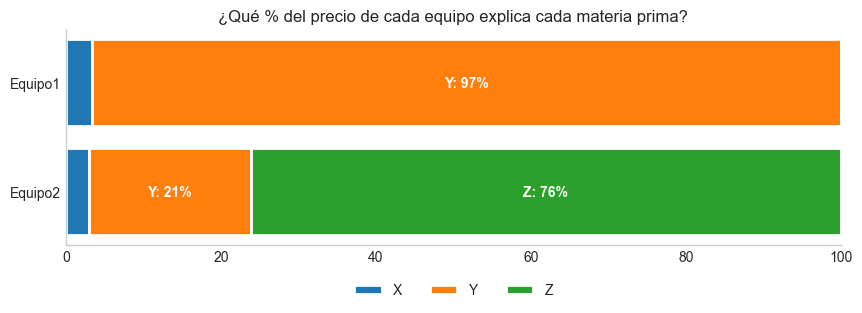

In [7]:
fig, ax = plt.subplots(figsize=(10, 2.8))
izq = np.zeros(2)
for ins in ["X", "Y", "Z"]:
    v = participacion[ins].values
    ax.barh(EQUIPOS, v, left=izq, color=COLORES[ins], label=ins, edgecolor="white", linewidth=2)
    for i, val in enumerate(v):
        if val > 5:
            ax.text(izq[i] + val / 2, i, f"{ins}: {val:.0f}%", ha="center", va="center", color="white", fontweight="bold")
    izq += v
ax.set_xlim(0, 100)
ax.invert_yaxis()
ax.set_title("¿Qué % del precio de cada equipo explica cada materia prima?")
ax.legend(ncol=3, loc="upper center", bbox_to_anchor=(0.5, -0.12))
ax.grid(False)
guardar(fig, "02_participacion_costo")

| Equipo | Modelo (unidades) | Lo que realmente mueve su costo |
|---|---|---|
| **Equipo 1** | 0.20 X + 0.80 Y | Y explica 97% del costo; X 3%; Z 0% |
| **Equipo 2** | 0.33 X + 0.33 Y + 0.33 Z | Z 76%, Y 21%, X 3% |

el riesgo del Equipo 1 es básicamente el riesgo de Y;
el del Equipo 2 es sobre todo el de Z. X es estadísticamente significativo pero pesa muy poco en pesos.

## 5. Confirmación con cambios mensuales: elasticidades y Lasso

Ahora se trabaja con cambios porcentuales mensuales para no tener tendencia. El coeficiente es una **elasticidad**: en otras palabras "si el insumo sube 1%, el equipo sube b%".

In [8]:
for e in EQUIPOS:
    res = rel.elasticidades(mensual, e)
    print(f"\n=== {e}   R² = {res.rsquared:.3f}")
    display(pd.DataFrame({"elasticidad": res.params, "p_valor": res.pvalues}).drop("const"))


=== Equipo1   R² = 0.993


,elasticidad,p_valor
X,0.0245,0.0001
Y,0.9662,0.0000
Z,0.0019,0.8748



=== Equipo2   R² = 0.989


,elasticidad,p_valor
X,0.0306,0.0000
Y,0.2011,0.0000
Z,0.7634,0.0000


Las elasticidades coinciden en el costo del método anterior (Equipo 1: Y ~0.97; Equipo 2: Z ~0.76, Y ~0.20).

Seguimos con **Lasso**, aplicamos la misma regresión, pero ahora aplicamos una multa en variables que no aportan, con validación cruzada temporal:

In [9]:
pd.DataFrame({e: rel.lasso_seleccion(mensual, e) for e in EQUIPOS}).T

,X,Y,Z
Equipo1,0.0336,0.9783,0.0000
Equipo2,0.0625,0.2827,0.8035


Lasso deja **Z en exactamente 0 para el Equipo 1** (la descarta como ruido) y conserva los tres insumos para el Equipo 2.

## 6. Estabilidad de la ecuación/formula 

Se calculan los pesos en ventanas móviles de 36 meses. Todo esto para revisar si cambia, por ejemplo, si un proveedor
cambia materiales, los pesos se podrían mover.

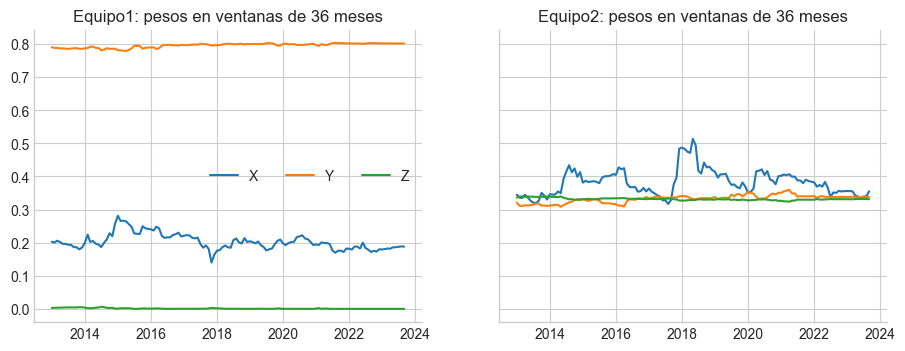

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
for ax, e in zip(axes, EQUIPOS):
    pm = rel.pesos_moviles(mensual, e)
    for ins in ["X", "Y", "Z"]:
        ax.plot(pm.index, pm[ins], color=COLORES[ins], label=ins)
    ax.set_title(f"{e}: pesos en ventanas de 36 meses")
axes[0].legend(ncol=3, loc="center right")
guardar(fig, "02_pesos_moviles")

Los pesos de Y y Z se mantienen prácticamente constantes desde 2013, la relación no es casual. El peso de X varía un poco más porque X es el insumo más barato: un pequeño error en pesos de X es poco dinero.

## 7. Validación fuera de muestra

Se entrenan los pesos solo con**2010-2019** y se predice **2020-2023** (incluye COVID y la guerra en Ucrania,
años muy volátiles) usando los precios reales de los insumos.

In [11]:
val = {e: rel.validacion_fuera_muestra(hist, e, "2019-12-31") for e in EQUIPOS}
pd.DataFrame({e: {"MAPE_%": v["MAPE_%"], "sesgo_%": v["sesgo_%"], "RMSE": v["RMSE"]} for e, v in val.items()}).T

,MAPE_%,sesgo_%,RMSE
Equipo1,1.5163,0.0056,9.5647
Equipo2,1.5035,-0.0076,17.8443


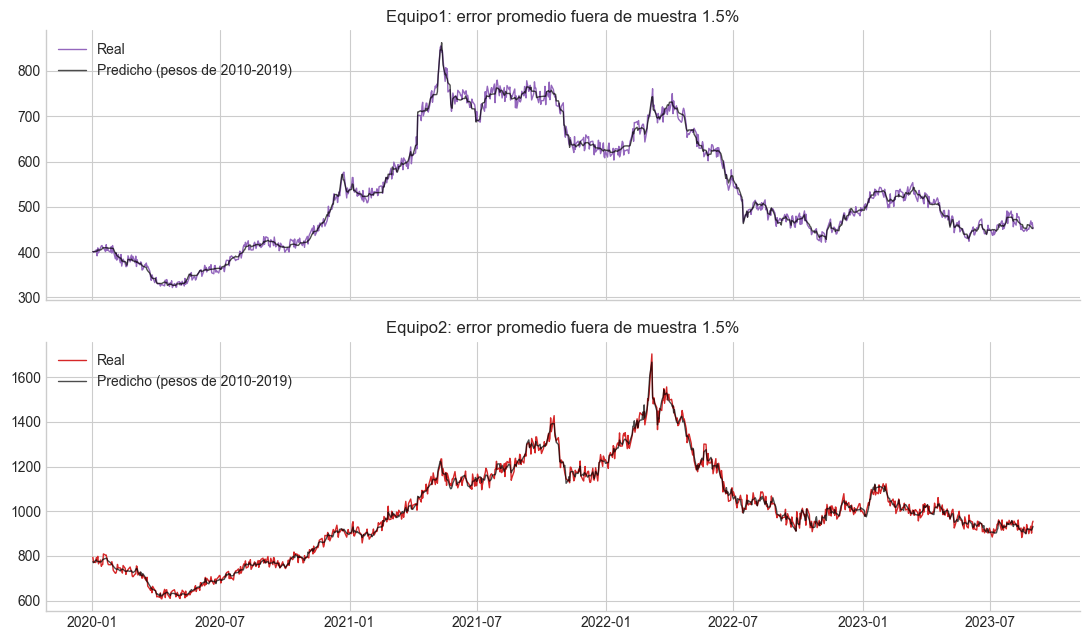

In [12]:
fig, axes = plt.subplots(2, 1, figsize=(11, 6.5), sharex=True)
for ax, e in zip(axes, EQUIPOS):
    real = hist.loc["2020":, e]
    ax.plot(real.index, real, color=COLORES[e], linewidth=1, label="Real")
    ax.plot(val[e]["pred"].index, val[e]["pred"], color="black", linewidth=1, alpha=0.7, label="Predicho (pesos de 2010-2019)")
    ax.set_title(f"{e}: error promedio fuera de muestra {val[e]['MAPE_%']:.1f}%")
    ax.legend(loc="upper left")
fig.tight_layout()
guardar(fig, "02_fuera_de_muestra")

## 8. Diagnóstico de residuos

Si lo que sobra (residuo) es ruido blanco (sin patrón, sin memoria), el modelo ya capturó toda la estructura
y no hay nada más que modelar con estos datos.

In [13]:
diag = {}
for e in EQUIPOS:
    res_d = hist[e] - hist[["X", "Y", "Z"]] @ pesos.loc[e]
    res_m = mensual[e] - mensual[["X", "Y", "Z"]] @ pesos.loc[e]
    diag[(e, "diario")] = rel.diagnostico_residuos(res_d, hist[e])
    diag[(e, "mensual")] = rel.diagnostico_residuos(res_m, mensual[e])
pd.DataFrame(diag).T

residuo_std_% residuo_media_% ljung_box_p ruido_blanco  \
Equipo1 diario         1.7475         -0.0324      0.8368         True   
        mensual        0.3742         -0.0030      0.0633         True   
Equipo2 diario         1.7282         -0.0214      0.0846         True   
        mensual        0.3049          0.0054      0.3966         True   

                estacionario_ADF  
Equipo1 diario              True  
        mensual             True  
Equipo2 diario              True  
        mensual             True

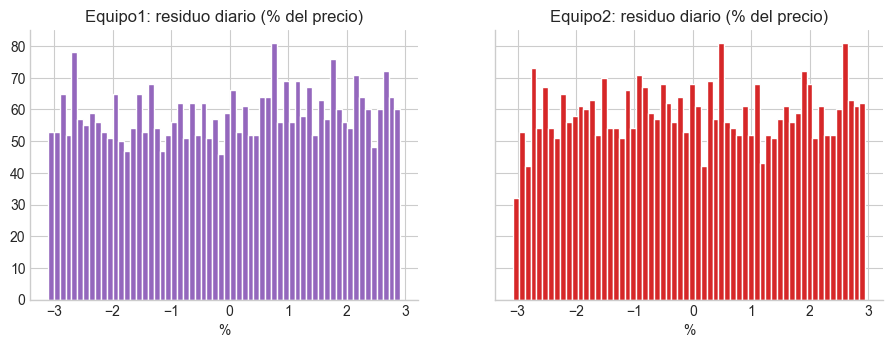

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5), sharey=True)
for ax, e in zip(axes, EQUIPOS):
    pct = 100 * (hist[e] - hist[["X", "Y", "Z"]] @ pesos.loc[e]) / hist[e]
    ax.hist(pct, bins=60, color=COLORES[e], edgecolor="white")
    ax.set_title(f"{e}: residuo diario (% del precio)")
    ax.set_xlabel("%")
guardar(fig, "02_residuos")

- Residuo diario: +1.7%/-1.7% (desviación estándar), centrado en 0, sin autocorrelación (Ljung-Box p > 0.05), estacionario.
- En promedio mensual el ruido baja a +0.3%/-0.3%, porque el ruido diario se cancela al promediar.

**Conclusión:** el precio de los equipos = modelo de insumos + un ruido diario pequeño e impredecible.

## 9. Uso práctico extra: evaluar cotizaciones de proveedores

El caso pide "una base para evaluar y comparar proveedores de forma objetiva". Con el modelo y el tamaño del ruido
se obtiene un **precio justo** con banda de tolerancia: una cotización fuera de la banda del 95% es atípica.

In [15]:
def precio_justo(equipo: str, x: float, y: float, z: float, cotizacion: float | None = None) -> dict:
    w = pesos.loc[equipo]
    justo = w["X"] * x + w["Y"] * y + w["Z"] * z
    sd = diag[(equipo, "diario")]["residuo_std_%"] / 100
    banda = (justo * (1 - 1.96 * sd), justo * (1 + 1.96 * sd))
    out = {"precio_justo": round(justo, 2), "banda_95%": tuple(round(b, 2) for b in banda)}
    if cotizacion is not None:
        out["diferencia_%"] = round(100 * (cotizacion / justo - 1), 2)
        out["veredicto"] = ("cara" if cotizacion > banda[1] else "barata" if cotizacion < banda[0] else "dentro de mercado")
    return out

ultimo = hist.iloc[-1]
print("Insumos del último día:", ultimo[["X", "Y", "Z"]].to_dict())

precio_justo("Equipo1", ultimo.X, ultimo.Y, ultimo.Z, cotizacion=480)

# precio_justo("Equipo2", 86.86, 545.0, 2165.25, cotizacion=920)
# precio_justo(equipo="Equipo1", x=90, y=600, z=2300, cotizacion=470)
# precio_justo("Equipo2", 90, 600, 2300)

# Con los precios de una fecha del histórico
#dia = hist.loc["2022-03-07"]
#precio_justo("Equipo2", dia.X, dia.Y, dia.Z, cotizacion=1750)                                                                                           

Insumos del último día: {'X': 86.86, 'Y': 545.0, 'Z': 2165.25}


{'precio_justo': np.float64(453.36),
 'banda_95%': (np.float64(437.83), np.float64(468.89)),
 'diferencia_%': np.float64(5.88),
 'veredicto': 'cara'}

## 10. Guardar el modelo

In [16]:
salida = pesos.copy()
salida["residuo_std_diario_%"] = [diag[(e, "diario")]["residuo_std_%"] for e in EQUIPOS]
salida["residuo_std_mensual_%"] = [diag[(e, "mensual")]["residuo_std_%"] for e in EQUIPOS]
salida.to_csv(datos.PROCESSED / "modelo_relacion.csv")
salida

,X,Y,Z,residuo_std_diario_%,residuo_std_mensual_%
Equipo1,0.1985,0.8002,0.0000,1.7475,0.3742
Equipo2,0.3347,0.3356,0.3325,1.7282,0.3049
